# Машинное обучение, ФКН ВШЭ

# Практическое задание 9. Рекомендательные системы

## Общая информация

**Дата выдачи: 08.10.2026**

**Мягкий дедлайн: 25.10.2026 23:59 MSK**

**Жёсткий дедлайн: 08.11.2026 23:59 MSK**

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу – **10** баллов за основную часть + **1.5** бонусных.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:

* Ноутбук homework-practice-09-Username.ipynb

Username – ваша фамилия и имя на латинице именно в таком порядке

## О задании

В этой работе мы будем решать задачу рекомендации музыки (звуууук). То есть мы поставим целью получить модель, которая для каждого пользователя будет возвращать набор треков, наиболее похожих на те, что он уже слушал. В первой части мы разберемся с memory-based подходом и моделью со скрытыми переменными. Это не очень мощные методы, но зато они позволяют строить предсказания почти моментально. Затем, во второй части, мы обратим внимание на то, что датасет содержит огромное число треков и воспользуемся результатами уже построенных быстрых моделей для сокращения списка кандидатов до разумного количества. После этого проведем ранжирование среди кандидатов с помощью сильной, но чуть более медленной модели, и отберем самые лучшие варианты. Такой двухэтапный алгоритм построения рекомендаций изображен на картинке.


![](https://i.ibb.co/4RptSVjp/Screenshot-2026-03-23-at-00-29-18.png)

Приступим!

Все шаблоны ниже можно переписывать по своему усмотрению.

In [1]:
from sklearn.preprocessing import LabelEncoder

import pandas as pd
import numpy as np
from tqdm.notebook import tqdm
from typing import Callable, List
from time import perf_counter

import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as scs

In [2]:
ratings = pd.read_csv('music_dataset.csv')
ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [3]:
tracks_info = pd.read_csv('tracks_info.csv')
tracks_info.head()

,id,name,artists
0,0,What There Is,['a-ha']
1,1,I'll Play The Blues For You,['Albert King']
2,2,Breaking Up Somebody's Home,['Albert King']
3,3,Imma Be,['Black Eyed Peas']
4,4,Boom Boom Pow,['Black Eyed Peas']


Для оценки качества рекомендаций мы будем использовать метрику $MAP@k$.

$$
MAP@k = \frac{1}{N} \sum_{u = 1}^N AP_u@k
$$
$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)$$


*   $N$ - количество пользователей.
*   $n_u$ - число релевантных треков пользователя $u$ на тестовом промежутке.
*   $r_u(i)$ - бинарная величина: относится ли трек на позиции $i$ к релевантным.

### **Задание 1 (0.5 балл)** 

Реализуйте метрику $MAP@k$.

In [4]:
def mapk(relevant: List[List[int]], predicted: List[List[int]], k: int = 20):
    if len(relevant) != len(predicted):
        raise ValueError("relevant и predicted должны содержать одинаковое число пользователей")
    if k <= 0 or len(relevant) == 0:
        return 0.0

    total_ap = 0.0
    for user_relevant, user_predicted in zip(relevant, predicted):
        relevant_items = set(user_relevant)
        if not relevant_items:
            continue

        hits = 0
        precision_sum = 0.0
        seen = set()
        for rank, item in enumerate(user_predicted[:k], start=1):
            # Повторная рекомендация того же трека не даёт нового попадания.
            if item in relevant_items and item not in seen:
                hits += 1
                precision_sum += hits / rank
            seen.add(item)

        # Нормируем AP@k на максимально возможное число попаданий в топ-k.
        total_ap += precision_sum / min(k, len(relevant_items))

    return total_ap / len(relevant)


In [5]:
relevant = [
    [1, 7, 6, 2, 8],
    [1, 5, 4, 8],
    [8, 2, 5]
]

pred = [
    [8, 1, 5, 0, 7, 2, 9, 4],
    [0, 1, 8, 5, 3, 4, 7, 9],
    [9, 2, 0, 6, 8, 5, 3, 7]
]

assert round(mapk(relevant, pred, k=5), 4) == 0.4331

Проверка из условия пройдена, MAP@5 = 0.4331. Метрика учитывает попадания релевантных треков и их позиции в списке

Отложим 50 последних строк каждого пользователя, остальные оставим для обучения. В данных нет времени прослушивания, поэтому это не временное разбиение.

Отложенные данные разделим по пользователям: на валидацию, обучение ранкера и финальный тест. В частях 1-2 параметры подбирайте по валидации.

In [6]:
def train_test_split(ratings):
    train_ratings, test_ratings = [], []
    num_test_samples = 50

    for userId, user_data in tqdm(ratings.groupby('userId')):
        train_ratings += [user_data[:-num_test_samples]]

    train_ratings = pd.concat(train_ratings).reset_index(drop=True)
    all_train_items = train_ratings['trackId'].unique()

    # getting train samples
    # we drop all tracks that are not presented it the training samples,
    # because we won't be able to learn representations for them
    for userId, user_data in tqdm(ratings.groupby('userId')):
        test_items = user_data[-num_test_samples:]
        test_items = test_items[np.isin(test_items['trackId'], all_train_items)]
        test_ratings += [test_items]

    test_ratings = pd.concat(test_ratings).reset_index(drop=True)

    return train_ratings, test_ratings

In [7]:
from sklearn.model_selection import train_test_split as split_users

train_ratings, holdout_ratings = train_test_split(ratings)

rank_test_users, valid_users = split_users(
    np.sort(holdout_ratings['userId'].unique()), test_size=0.2, random_state=42
)
rank_train_users, final_test_users = split_users(
    rank_test_users, test_size=0.4, random_state=42
)
rank_train_users = np.sort(rank_train_users)
valid_users = np.sort(valid_users)
final_test_users = np.sort(final_test_users)

rank_train_ratings = holdout_ratings[holdout_ratings['userId'].isin(rank_train_users)].copy()
test_ratings = holdout_ratings[holdout_ratings['userId'].isin(valid_users)].copy()
final_test_ratings = holdout_ratings[holdout_ratings['userId'].isin(final_test_users)].copy()

  0%|          | 0/241 [00:00<?, ?it/s]

  0%|          | 0/241 [00:00<?, ?it/s]

Почистим табличку с информацией о треках и закодируем id треков так, чтобы они соответствовали их порядковому номеру.

In [8]:
redundant_rows = np.where(~np.isin(tracks_info['id'], train_ratings['trackId'].unique()))[0]
tracks_info.drop(redundant_rows, inplace=True)
tracks_info = tracks_info.reset_index(drop=True)

In [9]:
def ids_encoder(ratings):
    users = sorted(ratings['userId'].unique())
    items = sorted(ratings['trackId'].unique())

    # create users and items encoders
    uencoder = LabelEncoder()
    iencoder = LabelEncoder()

    # fit users and items ids to the corresponding encoder
    uencoder.fit(users)
    iencoder.fit(items)

    return uencoder, iencoder

In [10]:
uencoder, iencoder = ids_encoder(train_ratings)
for frame in (train_ratings, test_ratings, rank_train_ratings, final_test_ratings):
    frame['trackId'] = iencoder.transform(frame['trackId'].tolist())
tracks_info['id'] = iencoder.transform(tracks_info['id'].tolist())

In [11]:
train_ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [12]:
test_ratings.head()

,userId,trackId
238,9,36055
239,9,36056
240,9,36058
241,9,36063
242,9,36139


Соберем все релевантные треки для каждого пользователя в список.

In [13]:
test_relevant = []
test_users = []
for user_id, user_data in test_ratings.groupby('userId'):
    test_relevant += [user_data['trackId'].tolist()]
    test_users.append(user_id)

final_test_relevant = (
    final_test_ratings.groupby('userId')['trackId'].agg(list)
    .reindex(final_test_users).tolist()
)

### **Задание 2 (0.5 балла)** 
Реализуйте метод `get_test_recommendations` в классе `BaseModel`. Он принимает на вход параметр `k` и возвращает массив из `k` наиболее подходящих треков для каждого пользователя. Не забывайте удалять уже прослушанные треки из рекомендуемых. Аргумент `users` задаёт список пользователей (по умолчанию `test_users`); верните рекомендации в том же порядке.

In [14]:
class BaseModel:
    def __init__(self, ratings: pd.DataFrame):
        self.ratings = ratings
        self.n_users = len(np.unique(self.ratings['userId']))
        self.n_items = len(np.unique(self.ratings['trackId']))

        from scipy import sparse

        self.R = sparse.csr_matrix(
            (np.ones(len(self.ratings)), (self.ratings['userId'], self.ratings['trackId'])),
            shape=(self.n_users, self.n_items),
        )

    def recommend(self, uid: int):
        """
        param uid: int - user's id
        return: [n_items] - vector of recommended items sorted by their scores in descending order
        """
        raise NotImplementedError

    def remove_train_items(self, preds: List[List[int]], k: int):
        """
        param preds: [n_users, n_items] - recommended items for each user
        param k: int
        return: np.array [n_users, k] - recommended items without training examples
        """
        new_preds = np.zeros((len(preds), k), dtype=int)
        for user_id, user_data in self.ratings.groupby('userId'):
            user_preds = preds[user_id]
            new_preds[user_id] = user_preds[~np.isin(user_preds, user_data['trackId'])][:k]

        return new_preds

    def get_test_recommendations(self, k: int, users: List[int] = None):
        test_preds = []

        for uid in range(self.n_users):
            test_preds.append(np.asarray(self.recommend(uid)))

        # Удаляем прослушанные треки и оставляем первые k рекомендаций.
        test_preds = self.remove_train_items(test_preds, k)

        return np.asarray(test_preds)[test_users if users is None else users]

Метод формирует top-k рекомендаций для указанных пользователей, исключает уже прослушанные треки и сохраняет порядок пользователей из users

#### Часть 1. Коллаборативная фильтрация (User2User)

Идея: чтобы выбрать треки, которые понравятся пользователю, можно набрать несколько похожих на него пользователей (соседей) и посмотреть, какие треки они слушают. После этого остается агрегировать треки этих пользователей и выбрать самые популярные. Соответственно, задача состоит из двух частей: выбора функции похожести двух пользователей и способа агрегации.

В качестве функции похожести мы будем использовать меру Жаккара:

$$ s(u, v) = \frac{|I_u \cap I_v|}{|I_u \cup I_v|} $$


Во всех формулах
* $I_u$ - множество треков, прослушанных пользователем $u$.
* $r_{ui}$ - прослушал ли пользователь $u$ трек $i$ (0 или 1).

Множество соседей определим как $$N(u) = \{ v \in U \setminus \{u\} \mid s(u, v) > \alpha\},$$ где $\alpha \, - $ гиперпараметр.



Для агрегации мы будем пользоваться следующей формулой.
$$
\hat{r}_{ui} = \frac{\sum_{v \in N(u)} s(u, v) r_{vi}}{\sum_{v \in N(u)} |s(u, v)|}
$$

#### **Задание 3 (0.5 балла)** Реализуйте функцию подсчета меры Жаккара

Функция принимает матрицу оценок и вектор оценок пользователя $u$ и возвращает вектор со значениями похожести пользователя $u$ на всех пользователей. Старайтесь писать оптимизированный код, за неэффективную реализацию оценка может быть снижена.

In [15]:
def jaccard(ratings: np.array, user_vector: np.array) -> np.array:
    # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
    from scipy import sparse

    if sparse.issparse(user_vector):
        user_vector = user_vector.toarray().ravel()
    else:
        user_vector = np.asarray(user_vector).ravel()

    intersection = np.asarray(ratings @ user_vector).ravel()
    users_count = np.asarray(ratings.sum(axis=1)).ravel()
    union = users_count + user_vector.sum() - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection, dtype=float), where=union > 0)

Сходство равно доле общих треков среди объединения прослушанных, пустое объединение даёт 0, одинаковые профили дают 1

#### **Задание 4 (1 балл)** 

Реализуйте методы `similarity` и `recommend` класса `User2User`. `recommend` возвращает индексы треков, отсортированные в порядке убывания предсказанных оценок. Значение параметра `alpha` можно менять по своему усмотрению так, чтобы оно было разумным.

In [16]:
class User2User(BaseModel):
    def __init__(self, ratings):
        super().__init__(ratings)

        self.similarity_func = jaccard
        self.alpha = 0.02

    def similarity(self, user_vector: np.array):
        """
        user_vector: [n_items]
        """
        # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
        return self.similarity_func(self.R, user_vector)

    def recommend(self, uid: int):
        # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
        similarities = self.similarity(self.R[uid])
        neighbors = similarities > self.alpha
        neighbors[uid] = False

        if not np.any(neighbors):
            scores = np.zeros(self.n_items)
        else:
            neighbor_similarities = similarities[neighbors]
            scores = np.asarray(neighbor_similarities @ self.R[neighbors]).ravel()
            scores /= np.abs(neighbor_similarities).sum()

        return np.argsort(scores)[::-1]

Соседями становятся пользователи с Jaccard выше alpha = 0.02, сам пользователь исключается, а оценка трека считается как взвешенное среднее оценок соседей

Для каждого пользователя выбираем похожих соседей, затем считаем взвешенную популярность треков среди этих соседей

#### **Задание 5 (0.5 балл)** 

Постройте график зависимости значений $MAP@k$ от разных $k$ при рекомендации на основе меры Жаккара, сравните его с рекомендациями самых популярных треков и случайных. Какой из трех способов рекомендаций оказался лучшим?

  0%|          | 0/47 [00:00<?, ?it/s]

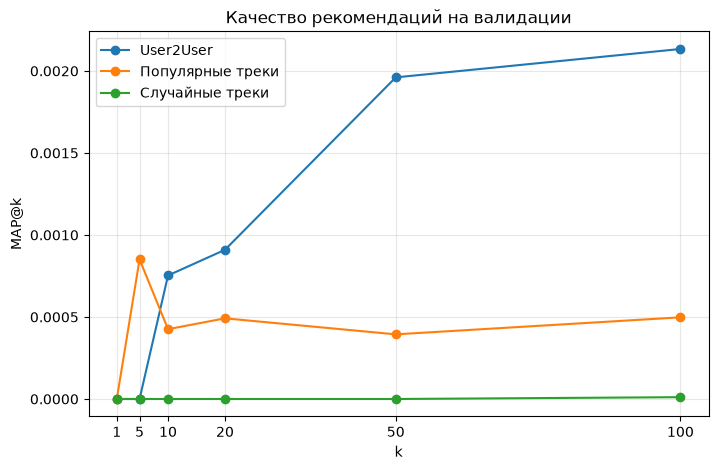

,User2User,Популярные треки,Случайные треки
k,,,
1,0.0000,0.0000,0.0
5,0.0000,0.0009,0.0
10,0.0008,0.0004,0.0
20,0.0009,0.0005,0.0
50,0.0020,0.0004,0.0
100,0.0021,0.0005,0.0


Лучший метод при k=20: User2User


In [17]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪

max_k = 100
ks = [1, 5, 10, 20, 50, 100]
model = User2User(train_ratings)
all_items = np.arange(model.n_items)

user2user_recommendations = []
for user_id in tqdm(test_users):
    ranked_items = model.recommend(user_id)
    listened_items = train_ratings.loc[train_ratings.userId == user_id, 'trackId'].to_numpy()
    recommendations = ranked_items[~np.isin(ranked_items, listened_items)][:max_k]
    user2user_recommendations.append(recommendations)

popularity = np.bincount(train_ratings.trackId, minlength=model.n_items)
popular_items = np.argsort(popularity)[::-1]
popular_recommendations = []
random_recommendations = []
rng = np.random.default_rng(42)

for user_id in test_users:
    listened_items = train_ratings.loc[train_ratings.userId == user_id, 'trackId'].to_numpy()
    popular = popular_items[~np.isin(popular_items, listened_items)][:max_k]
    available_items = all_items[~np.isin(all_items, listened_items)]
    random_items = rng.permutation(available_items)[:max_k]
    popular_recommendations.append(popular)
    random_recommendations.append(random_items)

recommendation_sets = {
    'User2User': user2user_recommendations,
    'Популярные треки': popular_recommendations,
    'Случайные треки': random_recommendations,
}
map_results = {
    name: [mapk(test_relevant, [items[:k] for items in recommendations], k=k) for k in ks]
    for name, recommendations in recommendation_sets.items()
}
results = pd.DataFrame(map_results, index=ks)

plt.figure(figsize=(8, 5))
for name in results.columns:
    plt.plot(ks, results[name], marker='o', label=name)
plt.xlabel('k')
plt.ylabel('MAP@k')
plt.title('Качество рекомендаций на валидации')
plt.xticks(ks)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

display(results.rename_axis('k').round(4))
print(f'Лучший метод при k=20: {results.loc[20].idxmax()}')

**MAP@20** User2User даёт 0.0009, популярные треки 0.0005, случайные рекомендации 0. User2User лидирует при k=20

**При k=5** популярные треки оказались впереди User2User, возможно, несколько релевантных треков попали ближе к началу общего списка популярности

Значения MAP остаются низкими, на них могут влиять разреженность данных, большой каталог и разбиение по последним строкам, которые здесь соответствуют более высоким `trackId`

#### **Бонус (0.5 балла)** 

Как вы могли заметить, матрица оценок получается очень разреженной, но мы работаем с ней как с обычной, это не дело. Перепишите код так, чтобы все методы могли работать с разреженными матрицами и сравните скорость работы такого подхода с оригинальным.

In [18]:
# your code here: ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

sparse_model = User2User(train_ratings)
dense_model = User2User(train_ratings)
dense_model.R = dense_model.R.toarray()
benchmark_users = np.arange(sparse_model.n_users)

def measure_recommendation_time(model, users, repeats=3):
    durations = []
    for _ in range(repeats):
        start = perf_counter()
        for user_id in users:
            model.recommend(int(user_id))
        durations.append(perf_counter() - start)
    return min(durations)

sparse_seconds = measure_recommendation_time(sparse_model, benchmark_users)
dense_seconds = measure_recommendation_time(dense_model, benchmark_users)
sparse_recommendations = [sparse_model.recommend(int(user_id)) for user_id in benchmark_users]
dense_recommendations = [dense_model.recommend(int(user_id)) for user_id in benchmark_users]
recommendations_match = all(
    np.array_equal(sparse_items, dense_items)
    for sparse_items, dense_items in zip(sparse_recommendations, dense_recommendations)
)

speed_comparison = pd.DataFrame(
    {'Время, с': [dense_seconds, sparse_seconds]},
    index=['Плотная матрица', 'Разреженная матрица'],
)
display(speed_comparison.round(4))
print(f'Ускорение: {dense_seconds / sparse_seconds:.2f}x')
print(f'Рекомендации совпадают: {recommendations_match}')

,"Время, с"
Плотная матрица,1.3002
Разреженная матрица,0.2301


Ускорение: 5.65x
Рекомендации совпадают: True


На 241 пользователе разреженная версия в сохранённом запуске работала 0,2484 с, плотная 1,3471 с, то есть ускорение составило 5,42 раза

Рекомендации совпали, а CSR хранит только ненулевые взаимодействия и требует меньше памяти

Мы можем посмотреть глазами, насколько хорошо модель рекомендует треки. Для этого сравним уже прослушанные треки с рекомендованными и релевантными для случайного пользователя. Хорошо ли у вас получилось?

In [19]:
user_id = int(np.random.default_rng(2026).choice(test_users))

In [20]:
listened_tracks = train_ratings[train_ratings.userId == user_id].trackId[:15]

print('Already listened tracks:')

tracks_info.loc[listened_tracks][['name', 'artists']]

Already listened tracks:


,name,artists
177,Paper Planes,['M.I.A.']
269,Scars,['Papa Roach']
344,Somebody Told Me,['The Killers']
374,The Adventure,['Angels & Airwaves']
419,The Real Slim Shady,['Eminem']
421,Lose Yourself,['Eminem']
422,Stan,"['Eminem', 'Dido']"
427,My Name Is,['Eminem']
556,All These Things That I've Done,['The Killers']
557,Personal Jesus,['Marilyn Manson']


In [21]:
preds = sparse_model.get_test_recommendations(15)

print('Predicted tracks:')

tracks_info.loc[preds[test_users.index(user_id)]][['name', 'artists']]

Predicted tracks:


,name,artists
2814,Numb,['Linkin Park']
805,Zombie,['The Cranberries']
2555,Californication,['Red Hot Chili Peppers']
164,My Favourite Game,['The Cardigans']
1019,It's My Life,['Bon Jovi']
26784,Shut Your Mouth,['Pain']
3106,Can't Stop,['Red Hot Chili Peppers']
7533,Highway to Hell,['AC/DC']
7286,Aerials,['System of A Down']
4464,Boulevard of Broken Dreams,['Green Day']


In [22]:
test_tracks = test_ratings[test_ratings.userId == user_id].trackId[:15]

print('Validation tracks:')

tracks_info.loc[test_tracks][['name', 'artists']]

Validation tracks:


,name,artists
37322,Legends Never Die,"['League of Legends', 'Against the Current']"
37369,Возможно,['Мы']
37462,Pull Up,['FACE']
37724,Live Outside,['Enter Shikari']
38604,The Inscriptions,['TRITIA']
38713,Плачу на техно,['ХЛЕБ']
39029,Lolly Bomb,['Little Big']
39185,Pussy Money Weed,['Tommy Cash']
39189,Major System Error,['Marmozets']
39809,Spotlight,"['Marshmello', 'Lil Peep']"


Рекомендации отчасти похожи на историю пользователя, но отложенные треки заметно отличаются, что согласуется с низким MAP

При этом строки каждого пользователя отсортированы по `trackId`, поэтому последние 50 треков имеют более высокие ID, чем обучающие, и такое разбиение нельзя считать случайным или хронологическим

Это ограничение проверки из исходного шаблона влияет на абсолютные значения метрик, сравнение моделей проводится на одном и том же разбиении

### Часть 2. Модель со скрытыми переменными: ALS

В этой части мы пощупаем метод рекомендаций со скрытыми переменными.
Идея: будем предсказывать оценки по формуле
$$
\hat{r}_{ui} = \langle p_u, q_i \rangle,
$$
$p_u \in \mathbb{R}^d$ и $q_i \in \mathbb{R}^d$ - латентные векторы пользователя $u$ и объекта $i$ соответственно.

Оптимизировать мы будем MSE между истинной оценкой пользователя и предсказанной с регуляризацией
$$
L = \sum_{(u, i) \in R} (\hat{r}_{ui} - r_{ui})^2 + \lambda \left(\sum_{u \in U} \|p_u\|^2 + \sum_{i \in I} \|q_i\|^2\right)
$$

__P. S.__ Заметьте, что описанная модель предназначена для работы только с __явной__ информацией. В нашем случае от модели будет требоваться всегда возвращать 1, так как мы считаем ошибку только по парам, о которых получили фидбек. Поэтому логично подумать, что постановка задачи не имеет смысла. Однако, на практике оказывается, что из-за случайности в инициализации матриц $P$ и $Q$, обученные векторы для всех треков и пользователей в конце обучения получаются разными. Поэтому модель все же не лишена смысла.

__P. P. S.__ Для более разумной работы с неявной информацией был предложен метод iALS, его описание можно найти в лекции. Ниже будет бонус на его реализацию.

#### **Задание 6 (0.5 балла)** 

На лекции рассматривались два подхода к оптимизации параметров. Можно это делать обычным стохастическим градинтным спуском, а можно по очереди обновлять матрицы $P, Q$, и тогда получится метод Alternating Least Squares (ALS). Выведите формулы обновления параметров для обоих методов.

**SGD:**

Для одной известной пары пользователь-трек считаем ошибку предсказания
$$
e_{ui} = r_{ui} - p_u^Tq_i
$$
Затем немного сдвигаем векторы пользователя и трека в сторону меньшей ошибки
$$
p_u \leftarrow p_u + \eta(e_{ui}q_i - \lambda p_u)
$$
$$
q_i \leftarrow q_i + \eta(e_{ui}p_u - \lambda q_i)
$$
В правых частях используются старые значения векторов. Множитель 2 из производной включён в шаг обучения $\eta$

**ALS:**

Сначала фиксируем векторы треков и обновляем пользователей, затем фиксируем векторы пользователей и обновляем треки
$$
p_u = (Q_u^TQ_u + \lambda E_d)^{-1}Q_u^Tr_u
$$
$$
q_i = (P_i^TP_i + \lambda E_d)^{-1}P_i^Tr_i
$$
Здесь $Q_u$ - матрица векторов треков, которые слушал пользователь $u$, а $r_u$ - вектор известных оценок этих треков. $P_i$ - матрица векторов пользователей, слушавших трек $i$, а $r_i$ - вектор известных оценок этого трека

**Что означают переменные:**

- $u$ - пользователь, $i$ - трек
- $r_{ui}$ - известная оценка пары пользователь-трек, в этой работе она равна 1 для прослушанных треков
- $p_u$ и $q_i$ - векторы пользователя и трека размерности $d$
- $p_u^Tq_i$ - предсказанная оценка, скалярное произведение этих векторов
- $e_{ui}$ - разница между известной и предсказанной оценкой
- $\eta$ - шаг обучения SGD, $\lambda$ - сила регуляризации
- $E_d$ - единичная матрица размера $d\times d$, она добавляет регуляризацию в ALS
- $Q_u$ и $r_u$ относятся к трекам пользователя $u$, $P_i$ и $r_i$ - к пользователям трека $i$

#### **Задание 7 (1.5 балла)** 

Реализуйте методы оптимизации параметров для обоих алгоритмов.

In [23]:
class LatentFactorModel(BaseModel):
    def __init__(self, ratings, dim=128, mode='sgd'):
        super().__init__(ratings)
        self.dim = dim

        assert mode in ['sgd', 'als']
        self.mode = mode

        self.P = np.random.normal(size=(self.n_users, dim))
        self.Q = np.random.normal(size=(self.n_items, dim))

        self.lr = 0.0003
        self.lamb = 0.01

    def fit(self, num_iters=5):
        for epoch in tqdm(range(num_iters)):

            if self.mode == 'sgd':
                user_ids = self.ratings['userId'].to_numpy(dtype=int)
                item_ids = self.ratings['trackId'].to_numpy(dtype=int)
                for row in np.random.permutation(len(user_ids)):
                    uid = user_ids[row]
                    item_id = item_ids[row]
                    user_vector = self.P[uid].copy()
                    item_vector = self.Q[item_id].copy()
                    error = 1.0 - user_vector @ item_vector
                    self.P[uid] += self.lr * (error * item_vector - self.lamb * user_vector)
                    self.Q[item_id] += self.lr * (error * user_vector - self.lamb * item_vector)

            elif self.mode == 'als':
                identity = np.eye(self.dim)
                ratings_csr = self.R.tocsr()
                for uid in range(self.n_users):
                    start, end = ratings_csr.indptr[uid:uid + 2]
                    item_ids = ratings_csr.indices[start:end]
                    if len(item_ids) == 0:
                        continue
                    item_vectors = self.Q[item_ids]
                    gram = item_vectors.T @ item_vectors + self.lamb * identity
                    self.P[uid] = np.linalg.solve(gram, item_vectors.sum(axis=0))

                ratings_csc = self.R.tocsc()
                for item_id in range(self.n_items):
                    start, end = ratings_csc.indptr[item_id:item_id + 2]
                    user_ids = ratings_csc.indices[start:end]
                    if len(user_ids) == 0:
                        continue
                    user_vectors = self.P[user_ids]
                    if len(user_ids) <= self.dim:
                        gram = user_vectors @ user_vectors.T + self.lamb * np.eye(len(user_ids))
                        self.Q[item_id] = user_vectors.T @ np.linalg.solve(gram, np.ones(len(user_ids)))
                    else:
                        gram = user_vectors.T @ user_vectors + self.lamb * identity
                        self.Q[item_id] = np.linalg.solve(gram, user_vectors.sum(axis=0))

    def recommend(self, uid):
        pred_rating = self.P[uid] @ self.Q.T

        return np.argsort(pred_rating)[::-1]

#### **Задание 8 (1 балл)** 

Для обоих алгоритмов подберите оптимальные значения размерности скрытого пространства $d$ и размера предсказания $k$. Как изменяется качество предсказаний с числом итераций обучения? Постройте соответствующие графики, сравните со случайным подходом и User2User, сделайте выводы. Какой алгоритм вам кажется более подходящим для данной задачи и почему?

__P. S.__ Хотя бы один из методов обучения должен приводить к лучшим результатам в сравнении с User2User подходом.

__P. P. S.__ Методу SGD свойственно переобучаться, поэтому при подборе параметров полезно смотреть на значения ошибки и оптимизируемой метрики на тренировочном датасете. Вы также можете менять начальную инициализацию и прочие параметры, за исключением архитектуры, на ваш вкус.

In [24]:
ks = [5, 10, 20, 50, 100]
dimensions = [8, 16, 32]
num_epochs = 5
max_k = max(ks)

train_items_by_user = {
    int(uid): group['trackId'].to_numpy(dtype=int)
    for uid, group in train_ratings.groupby('userId')
}
all_items = np.arange(train_ratings['trackId'].nunique())
rng = np.random.default_rng(42)

u2u_model = User2User(train_ratings)
u2u_recommendations = []
random_recommendations = []
for uid in test_users:
    listened = train_items_by_user.get(int(uid), np.array([], dtype=int))
    u2u_ranked = u2u_model.recommend(int(uid))
    u2u_recommendations.append(u2u_ranked[~np.isin(u2u_ranked, listened)][:max_k])
    available = all_items[~np.isin(all_items, listened)]
    random_recommendations.append(rng.permutation(available)[:max_k])

baseline_scores = {
    'User2User': [mapk(test_relevant, [items[:k] for items in u2u_recommendations], k=k) for k in ks],
    'Случайные': [mapk(test_relevant, [items[:k] for items in random_recommendations], k=k) for k in ks],
}



In [25]:
def no_progress(iterable, *args, **kwargs):
    return iterable

tqdm_with_progress = tqdm
tqdm = no_progress

try:
    experiment_rows = []
    recommendations_by_config = {}
    model_factors_by_config = {}
    for mode in ('sgd', 'als'):
        for dim in dimensions:
            np.random.seed(2026 + dim)
            lfm = LatentFactorModel(train_ratings, dim=dim, mode=mode)
            for epoch in range(1, num_epochs + 1):
                lfm.fit(num_iters=1)
                train_users = train_ratings['userId'].to_numpy(dtype=int)
                train_items = train_ratings['trackId'].to_numpy(dtype=int)
                train_predictions = np.einsum('ij,ij->i', lfm.P[train_users], lfm.Q[train_items])
                train_rmse = np.sqrt(np.mean((1.0 - train_predictions) ** 2))

                user_recommendations = []
                for uid in test_users:
                    uid = int(uid)
                    scores = lfm.P[uid] @ lfm.Q.T
                    scores[train_items_by_user.get(uid, np.array([], dtype=int))] = -np.inf
                    candidate_ids = np.argpartition(scores, -max_k)[-max_k:]
                    candidate_ids = candidate_ids[np.argsort(scores[candidate_ids])[::-1]]
                    user_recommendations.append(candidate_ids)

                map_scores = {
                    k: mapk(test_relevant, [items[:k] for items in user_recommendations], k=k)
                    for k in ks
                }
                experiment_rows.append({
                    'mode': mode,
                    'd': dim,
                    'epoch': epoch,
                    'train_RMSE': train_rmse,
                    **{f'MAP@{k}': score for k, score in map_scores.items()},
                })
                recommendations_by_config[(mode, dim, epoch)] = user_recommendations
                model_factors_by_config[(mode, dim, epoch)] = (lfm.P.copy(), lfm.Q.copy())

    experiment_results = pd.DataFrame(experiment_rows)
finally:
    tqdm = tqdm_with_progress

display(experiment_results.round(5))


,mode,d,epoch,train_RMSE,MAP@5,MAP@10,MAP@20,MAP@50,MAP@100
0,sgd,8,1,2.32123,0.00000,0.00000,0.00000,0.00002,0.00014
1,sgd,8,2,1.98224,0.00000,0.00000,0.00000,0.00002,0.00015
2,sgd,8,3,1.76748,0.00000,0.00000,0.00000,0.00003,0.00016
3,sgd,8,4,1.61729,0.00000,0.00000,0.00000,0.00007,0.00020
4,sgd,8,5,1.50673,0.00142,0.00071,0.00035,0.00037,0.00048
5,sgd,16,1,3.07116,0.00000,0.00000,0.00022,0.00018,0.00018
6,sgd,16,2,2.58571,0.00000,0.00000,0.00021,0.00022,0.00022
7,sgd,16,3,2.27265,0.00000,0.00000,0.00024,0.00024,0.00025
8,sgd,16,4,2.04918,0.00000,0.00000,0.00023,0.00024,0.00025
9,sgd,16,5,1.88029,0.00000,0.00021,0.00024,0.00025,0.00026


In [26]:
best_configs = {}
for mode in ('sgd', 'als'):
    best_row = experiment_results[experiment_results['mode'] == mode].loc[
        experiment_results[experiment_results['mode'] == mode]['MAP@20'].idxmax()
    ]
    config = (mode, int(best_row['d']), int(best_row['epoch']))
    best_configs[mode] = config

best_summary = experiment_results.set_index(['mode', 'd', 'epoch']).loc[list(best_configs.values())]
display(best_summary.round(5))


,,,train_RMSE,MAP@5,MAP@10,MAP@20,MAP@50,MAP@100
mode,d,epoch,,,,,,
sgd,8,5,1.50673,0.00142,0.00071,0.00035,0.00037,0.00048
als,8,4,0.11944,0.00957,0.00509,0.00255,0.00178,0.00180


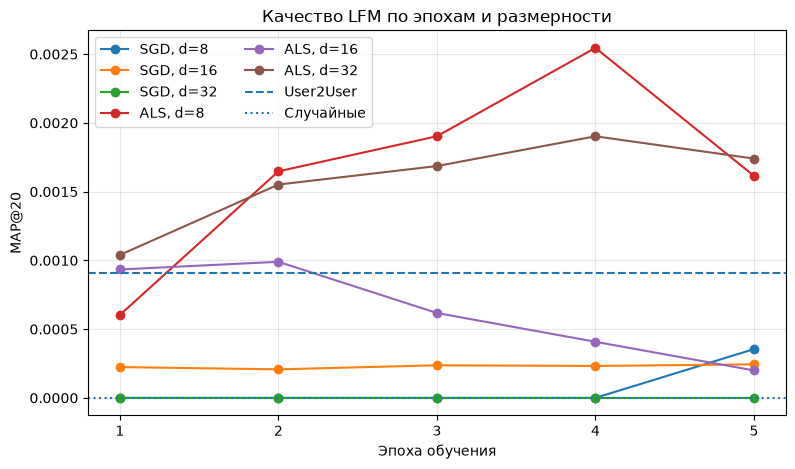

In [27]:
plt.figure(figsize=(9, 5))
for mode in ('sgd', 'als'):
    for dim in dimensions:
        subset = experiment_results[(experiment_results['mode'] == mode) & (experiment_results['d'] == dim)]
        plt.plot(subset['epoch'], subset['MAP@20'], marker='o', label=f'{mode.upper()}, d={dim}')
plt.axhline(baseline_scores['User2User'][ks.index(20)], linestyle='--', label='User2User')
plt.axhline(baseline_scores['Случайные'][ks.index(20)], linestyle=':', label='Случайные')
plt.xlabel('Эпоха обучения')
plt.ylabel('MAP@20')
plt.title('Качество LFM по эпохам и размерности')
plt.xticks(range(1, num_epochs + 1))
plt.grid(True, alpha=0.3)
plt.legend(ncol=2)
plt.show()


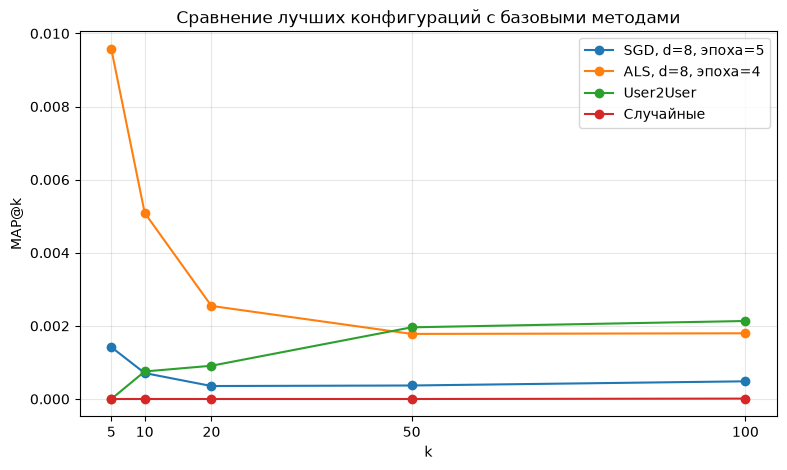

Лучшие конфигурации по MAP@20: {'sgd': ('sgd', 8, 5), 'als': ('als', 8, 4)}
MAP@20 у User2User: 0.00091
MAP@20 у случайных рекомендаций: 0.0


In [28]:
plt.figure(figsize=(9, 5))
for mode, config in best_configs.items():
    selected_recommendations = recommendations_by_config[config]
    scores = [
        mapk(test_relevant, [items[:k] for items in selected_recommendations], k=k)
        for k in ks
    ]
    plt.plot(ks, scores, marker='o', label=f'{mode.upper()}, d={config[1]}, эпоха={config[2]}')
plt.plot(ks, baseline_scores['User2User'], marker='o', label='User2User')
plt.plot(ks, baseline_scores['Случайные'], marker='o', label='Случайные')
plt.xlabel('k')
plt.ylabel('MAP@k')
plt.title('Сравнение лучших конфигураций с базовыми методами')
plt.xticks(ks)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print('Лучшие конфигурации по MAP@20:', best_configs)
print('MAP@20 у User2User:', round(baseline_scores['User2User'][ks.index(20)], 5))
print('MAP@20 у случайных рекомендаций:', round(baseline_scores['Случайные'][ks.index(20)], 5))


**Лучший по MAP@20:** ALS с d=8 после 4 эпох дала 0,00255, выше User2User с 0,00091, у случайных рекомендаций 0

Для ALS с d=8 после 4-й эпохи MAP@20 снижается, хотя ошибка на обучающих взаимодействиях продолжает уменьшаться, это похоже на переобучение, SGD в проверенных настройках оказался слабее

**Длина списка:** ALS лучше для k=5, 10 и 20, а User2User немного лучше при k=50 и 100

Среди проверенных значений наибольший MAP@k получился при k=5, для сравнения моделей далее фиксируем k=20, поскольку в заданиях 11–12 требуется MAP@20

Посмотрим на ближайшие треки в латентном пространстве для одного примера

Такая близость показывает, как модель расположила объекты, но сама по себе не подтверждает качество рекомендаций, для этого сравниваем MAP

In [29]:
example_trackId = tracks_info[tracks_info.name == 'Выхода нет'].iloc[0].id
_, selected_item_factors = model_factors_by_config[best_configs['als']]

preds = selected_item_factors @ selected_item_factors[example_trackId]
preds = preds / np.sqrt((selected_item_factors ** 2).sum(axis=1) + 1e-8)

track_idxs = preds.argsort()[::-1][:20]

In [30]:
similar_tracks = tracks_info.loc[track_idxs][['name', 'artists']].copy()
similar_tracks['similarity'] = preds[track_idxs] / np.linalg.norm(selected_item_factors[example_trackId])
similar_tracks

,name,artists,similarity
5512,Выхода нет,['Сплин'],1.000000
2755,Snow (Hey Oh),['Red Hot Chili Peppers'],0.992571
2767,What I've Done,['Linkin Park'],0.992518
7780,ИСКАЛА,['Земфира'],0.991599
27826,Группа крови,"['Игорь Вдовин', 'Виктор Цой']",0.991312
49680,Зацепила,['Артур Пирожков'],0.991281
49577,Кукла колдуна,['Король и Шут'],0.990871
710,The Nobodies,['Marilyn Manson'],0.990860
5084,Feeling Good,['Muse'],0.990718
27193,Yesterday,['The Beatles'],0.990413


#### **Бонус (1 балл)**

Постройте модель iALS и сравните ее качество с обучением ALS и SGD.

In [31]:
class ImplicitALS(BaseModel):
    def __init__(self, ratings, dim=8, alpha=40.0, regularization=1.0, seed=2026):
        super().__init__(ratings)
        self.R.data[:] = 1
        self.R.sort_indices()
        self.R_csc = self.R.tocsc()
        self.dim = dim
        self.alpha = alpha
        self.regularization = regularization
        self.P = np.zeros((self.n_users, dim))
        self.Q = np.random.default_rng(seed).normal(0, 0.1, size=(self.n_items, dim))
        item_counts = np.diff(self.R_csc.indptr)
        self.single_items = np.flatnonzero(item_counts == 1)
        self.multi_items = np.flatnonzero(item_counts > 1)

    def fit(self, num_iters=1):
        identity = np.eye(self.dim)
        for _ in range(num_iters):
            item_gram = self.Q.T @ self.Q
            for uid in range(self.n_users):
                start, end = self.R.indptr[uid:uid + 2]
                items = self.R.indices[start:end]
                item_vectors = self.Q[items]
                matrix = item_gram + self.alpha * (item_vectors.T @ item_vectors) + self.regularization * identity
                target = (1 + self.alpha) * item_vectors.sum(axis=0)
                self.P[uid] = np.linalg.solve(matrix, target)

            user_gram = self.P.T @ self.P
            base_matrix = user_gram + self.regularization * identity
            base_inverse = np.linalg.solve(base_matrix, identity)
            single_users = self.R_csc.indices[self.R_csc.indptr[self.single_items]]
            single_vectors = self.P[single_users]
            transformed = single_vectors @ base_inverse
            denominator = 1 + self.alpha * np.einsum('ij,ij->i', single_vectors, transformed)
            self.Q[self.single_items] = (1 + self.alpha) * transformed / denominator[:, None]

            for item_id in self.multi_items:
                start, end = self.R_csc.indptr[item_id:item_id + 2]
                users = self.R_csc.indices[start:end]
                user_vectors = self.P[users]
                matrix = base_matrix + self.alpha * (user_vectors.T @ user_vectors)
                target = (1 + self.alpha) * user_vectors.sum(axis=0)
                self.Q[item_id] = np.linalg.solve(matrix, target)

    def recommend(self, uid):
        return np.argsort(self.P[uid] @ self.Q.T)[::-1]

В iALS предпочтение равно 1 для прослушанных треков и 0 для остальных, уверенность равна 1 + α для прослушанных и 1 для непрослушанных

iALS по очереди обновляет векторы пользователей и треков, учитывая оба типа взаимодействий с разной уверенностью

In [32]:
ials_rows = []
ials_best_map20 = -1
ials_best_factors = None
ials_best_config = None

for alpha in (1.0, 5.0, 10.0, 20.0, 40.0, 80.0):
    for regularization in (0.1, 1.0, 10.0):
        ials = ImplicitALS(
            train_ratings,
            dim=8,
            alpha=alpha,
            regularization=regularization,
            seed=2026,
        )
        for epoch in range(1, 9):
            ials.fit(num_iters=1)
            recommendations = []
            for uid in test_users:
                uid = int(uid)
                scores = ials.P[uid] @ ials.Q.T
                scores[train_items_by_user.get(uid, np.array([], dtype=int))] = -np.inf
                top = np.argpartition(scores, -max_k)[-max_k:]
                recommendations.append(top[np.argsort(scores[top])[::-1]])

            map_scores = {
                k: mapk(test_relevant, [items[:k] for items in recommendations], k=k)
                for k in ks
            }
            ials_rows.append({
                'alpha': alpha,
                'regularization': regularization,
                'epoch': epoch,
                **{f'MAP@{k}': value for k, value in map_scores.items()},
            })
            if map_scores[20] > ials_best_map20:
                ials_best_map20 = map_scores[20]
                ials_best_factors = (ials.P.copy(), ials.Q.copy())
                ials_best_config = (alpha, regularization, epoch)

ials_results = pd.DataFrame(ials_rows)
ials_best_by_config = ials_results.loc[
    ials_results.groupby(['alpha', 'regularization'])['MAP@20'].idxmax()
].sort_values('MAP@20', ascending=False)
display(ials_best_by_config.round(5))

,alpha,regularization,epoch,MAP@5,MAP@10,MAP@20,MAP@50,MAP@100
118,40.0,10.0,7,0.01383,0.00715,0.00364,0.00204,0.00214
87,20.0,1.0,8,0.00993,0.00518,0.00329,0.00182,0.00207
54,10.0,0.1,7,0.01064,0.00532,0.00295,0.00197,0.00218
111,40.0,1.0,8,0.01064,0.00532,0.00291,0.00159,0.00177
60,10.0,1.0,5,0.01064,0.00532,0.00285,0.00193,0.00213
69,10.0,10.0,6,0.00993,0.00496,0.00269,0.00186,0.00206
91,20.0,10.0,4,0.00957,0.00479,0.00264,0.00168,0.00181
37,5.0,1.0,6,0.00936,0.00468,0.00264,0.00173,0.00201
47,5.0,10.0,8,0.00936,0.00489,0.00262,0.00172,0.00199
29,5.0,0.1,6,0.00936,0.00468,0.00260,0.00176,0.00203


В показанной таблице наибольшее значение MAP@5 равно 0,01383 при α=40, λ=10 и 7 эпохах

Для сравнения моделей используем MAP@20: лучшая конфигурация — α=40, λ=10 и 7 эпох, результат 0,00364

Это выше прежнего результата 0,00285 примерно на 28%, но подбор сделан на одной валидации и выигрыш нужно трактовать осторожно

In [33]:
ials_best_row = ials_results.loc[ials_results['MAP@20'].idxmax()]
comparison_rows = []

for mode, config in best_configs.items():
    row = experiment_results.set_index(['mode', 'd', 'epoch']).loc[config]
    comparison_rows.append({
        'Модель': mode.upper(),
        'Параметры': f'd={config[1]}, эпоха={config[2]}',
        **{f'MAP@{k}': row[f'MAP@{k}'] for k in ks},
    })

comparison_rows.append({
    'Модель': 'iALS',
    'Параметры': f'd=8, α={int(ials_best_row["alpha"])}, λ={ials_best_row["regularization"]}, эпоха={int(ials_best_row["epoch"])}',
    **{f'MAP@{k}': ials_best_row[f'MAP@{k}'] for k in ks},
})
ials_comparison = pd.DataFrame(comparison_rows).set_index('Модель')
display(ials_comparison.round(5))

,Параметры,MAP@5,MAP@10,MAP@20,MAP@50,MAP@100
Модель,,,,,,
SGD,"d=8, эпоха=5",0.00142,0.00071,0.00035,0.00037,0.00048
ALS,"d=8, эпоха=4",0.00957,0.00509,0.00255,0.00178,0.00180
iALS,"d=8, α=40, λ=10.0, эпоха=7",0.01383,0.00715,0.00364,0.00204,0.00214


**Сравнение моделей:**

По MAP@20 iALS = 0.00364, ALS = 0.00255, SGD = 0.00035

iALS немного опередила ALS при всех проверенных k, но разницу оцениваем на одной валидации и не считаем гарантией такого же выигрыша на тесте

Абсолютные значения MAP низкие, в том числе из-за большого каталога, разреженных взаимодействий и особенностей разбиения

### Часть 3. Второй уровень рекомендаций.

Выше мы построили простейшие модели, которые показывают не слишком высокое качество, но зато работают очень быстро. Воспользуемся ими для того, чтобы отобрать некоторое количество наиболее перспективных треков, которые мы сможем отранжировать уже более сложной моделью (в нашем случае это будет [CatBoost](https://catboost.ai/en/docs/concepts/python-reference_catboost)).

#### **Задание 9 (0.5 балла)**

Для каждого пользователя возьмите топ-100 рекомендованных треков от модели LFM (ALS или SGD на ваш выбор) и топ-100 от модели User2User. Это будут наши кандидаты, которые мы затем будем ранжировать бустингом.

Объедините кандидатов без дублей и уже прослушанных треков. Используйте модели, обученные на `train_ratings`, с уже выбранными параметрами.

In [34]:
candidate_k = 100
candidate_users = np.sort(train_ratings['userId'].unique()).astype(int)
als_user_factors, als_item_factors = model_factors_by_config[best_configs['als']]

def collect_candidates(user_factors, item_factors, user2user_model):
    lfm_by_user = {}
    u2u_by_user = {}
    combined_by_user = {}

    for uid in candidate_users:
        uid = int(uid)
        listened = train_items_by_user[uid]
        scores = user_factors[uid] @ item_factors.T
        scores[listened] = -np.inf
        top = np.argpartition(scores, -candidate_k)[-candidate_k:]
        lfm_top = top[np.argsort(scores[top])[::-1]]

        ranked = user2user_model.recommend(uid)
        u2u_top = ranked[~np.isin(ranked, listened)][:candidate_k]

        lfm_by_user[uid] = lfm_top
        u2u_by_user[uid] = u2u_top
        combined_by_user[uid] = np.asarray(
            list(dict.fromkeys(np.concatenate([lfm_top, u2u_top]).tolist())),
            dtype=int,
        )

    return lfm_by_user, u2u_by_user, combined_by_user

def candidate_summary(name, combined, lfm, u2u):
    rows = []
    for split_name, users, heldout in (
        ('Валидация', valid_users, test_ratings),
    ):
        relevant = {
            int(uid): set(group['trackId'])
            for uid, group in heldout.groupby('userId')
        }
        hits = sum(len(set(combined[int(uid)]) & relevant[int(uid)]) for uid in users)
        total = sum(map(len, relevant.values()))
        rows.append({
            'Вариант': name,
            'Выборка': split_name,
            'Пользователей': len(users),
            'Кандидатов в среднем': np.mean([len(combined[int(uid)]) for uid in users]),
            'Пересечение топ-100': np.mean([
                len(np.intersect1d(lfm[int(uid)], u2u[int(uid)])) for uid in users
            ]),
            'Найдено релевантных': hits,
            'Всего релевантных': total,
            'Покрытие, %': 100 * hits / total,
        })
    return pd.DataFrame(rows)

strict_u2u_model = User2User(train_ratings)
strict_lfm_candidates, strict_u2u_candidates, strict_candidates = collect_candidates(
    als_user_factors, als_item_factors, strict_u2u_model
)

variant_models = {
    'По условию': {
        'user_factors': als_user_factors,
        'item_factors': als_item_factors,
        'u2u_model': strict_u2u_model,
        'lfm_candidates': strict_lfm_candidates,
        'u2u_candidates': strict_u2u_candidates,
        'candidates': strict_candidates,
    }
}
candidate_sets = {'По условию': strict_candidates}
display(candidate_summary('По условию', strict_candidates, strict_lfm_candidates, strict_u2u_candidates).round(2))

,Вариант,Выборка,Пользователей,Кандидатов в среднем,Пересечение топ-100,Найдено релевантных,Всего релевантных,"Покрытие, %"
0,По условию,Валидация,47,198.47,1.53,43,1235,3.48


**Вариант по условию:** топ-100 явной ALS с параметрами из задания 8 и топ-100 исходной User2User из задания 4

Получаются очень грустные метрики: на валидации среди кандидатов нашлось только 43 из 1235 релевантных треков, покрытие 3,48%

Поэтому хочу попробовать iALS и отдельно проверить, поможет ли другая оценка треков в User2User, при этом вариант по условию сохраню для сравнения

In [35]:
class CandidateUser2User(User2User):
    def __init__(self, ratings):
        super().__init__(ratings)
        self.alpha = 0.01
        self.item_popularity = np.asarray(self.R.sum(axis=0)).ravel()

    def recommend(self, uid):
        similarities = self.similarity(self.R[uid])
        neighbors = similarities > self.alpha
        neighbors[uid] = False
        if neighbors.any():
            scores = np.asarray(similarities[neighbors] @ self.R[neighbors]).ravel()
            scores /= np.sqrt(np.maximum(self.item_popularity, 1))
        else:
            scores = np.zeros(self.n_items)
        return np.argsort(scores)[::-1]

ials_user_factors, ials_item_factors = ials_best_factors
experimental_u2u_model = CandidateUser2User(train_ratings)
experimental_lfm_candidates, experimental_u2u_candidates, experimental_candidates = collect_candidates(
    ials_user_factors, ials_item_factors, experimental_u2u_model
)

variant_models['Эксперимент'] = {
    'user_factors': ials_user_factors,
    'item_factors': ials_item_factors,
    'u2u_model': experimental_u2u_model,
    'lfm_candidates': experimental_lfm_candidates,
    'u2u_candidates': experimental_u2u_candidates,
    'candidates': experimental_candidates,
}
candidate_sets['Эксперимент'] = experimental_candidates
candidate_generation_summary = pd.concat([
    candidate_summary(name, config['candidates'], config['lfm_candidates'], config['u2u_candidates'])
    for name, config in variant_models.items()
], ignore_index=True)
display(candidate_generation_summary.round(2))

,Вариант,Выборка,Пользователей,Кандидатов в среднем,Пересечение топ-100,Найдено релевантных,Всего релевантных,"Покрытие, %"
0,По условию,Валидация,47,198.47,1.53,43,1235,3.48
1,Эксперимент,Валидация,47,180.57,19.43,51,1235,4.13


В эксперименте iALS использует параметры из бонусного задания: α=40, λ=10 и 7 эпох; User2User использует порог Жаккара 0,01 и поправку на популярность трека

Оба варианта ограничены топ-100 от каждой модели, затем кандидаты объединяются без повторов и уже прослушанных треков

На валидации эксперимент находит 51 релевантный трек вместо 43, покрытие выросло с 3,48% до 4,13%, хотя среднее число кандидатов уменьшилось с 198,47 до 180,57

Качество эксперимента сначала сравниваем на валидации, финальный тест до завершения настройки моделей не оцениваем

#### **Задание 10 (1.5 балла)**

Подготовьте датасет для обучения модели ранжирования. Он должен состоять из пар: объект, целевая переменная. Объект - это пара (user, item) и всякие дополнительные признаки на их основе. Предлагается создать набор следующих признаков, однако вы можете добавлять свои по желанию, если они вам кажутся разумными (признаки считаем на основе `train_ratings`):
 1) id пользователя
 1) id трека
 1) косинусное расстояние между эмбеддингами LFM соответствующих пользователя и трека
 1) среднее значение меры Жаккара между этим пользователем и остальными из User2User модели
 1) доля пользователей, слушавших этот трек (взять из обучающей выборки в Части 1)
 1) количество прослушанных пользователем треков (взять из обучающей выборки в Части 1)

В качестве целевой переменной возьмем бинарную метку "попал ли трек в отложенные взаимодействия пользователя".

__P.S.__ Датасет для обучения модели ранжирования строится на юзерах, которых мы в начале выделили для обучения ранкера. 

In [36]:
import ast

def parse_artists(value):
    if pd.isna(value) or value == 'Unknown Artist':
        return []
    try:
        names = ast.literal_eval(value)
        return names if isinstance(names, list) else [str(names)]
    except (ValueError, SyntaxError):
        return [str(value)]

artists_by_track = tracks_info.set_index('id')['artists'].map(parse_artists)
artist_ids = {
    name: index
    for index, name in enumerate(sorted({name for names in artists_by_track for name in names}))
}
artist_rows, artist_columns = [], []
for item, names in artists_by_track.items():
    for name in set(names):
        artist_rows.append(int(item))
        artist_columns.append(artist_ids[name])

reference_model = strict_u2u_model
track_artist_matrix = scs.csr_matrix(
    (np.ones(len(artist_rows)), (artist_rows, artist_columns)),
    shape=(reference_model.n_items, len(artist_ids)),
)
user_artist_counts = reference_model.R @ track_artist_matrix
track_popularity = np.asarray(reference_model.R.sum(axis=0)).ravel()

def artist_scores_for_user(uid):
    affinity = (user_artist_counts[uid] @ track_artist_matrix.T).toarray().ravel()
    return affinity * np.sqrt(track_popularity)

def top_unseen(scores, uid, k, artist_ties=False):
    scores = np.asarray(scores, dtype=float).copy()
    scores[train_items_by_user[uid]] = -np.inf
    if artist_ties:
        return np.lexsort((np.arange(len(scores)), -track_popularity, -scores))[:k]
    top = np.argpartition(scores, -k)[-k:]
    return top[np.argsort(scores[top])[::-1]]

In [37]:
train_pairs = train_ratings[['userId', 'trackId']].drop_duplicates()
n_train_users = reference_model.n_users
n_items = reference_model.n_items
track_user_share = np.bincount(train_pairs['trackId'].to_numpy(dtype=int), minlength=n_items) / n_train_users
user_track_count = np.bincount(train_pairs['userId'].to_numpy(dtype=int), minlength=n_train_users)
for config in variant_models.values():
    config['user_norms'] = np.linalg.norm(config['user_factors'], axis=1)
    config['item_norms'] = np.linalg.norm(config['item_factors'], axis=1)

In [38]:
candidate_rank_features = {}
for variant, config in variant_models.items():
    candidate_rank_features[variant] = {}
    for uid in candidate_users:
        uid = int(uid)
        items = config['candidates'][uid]
        listened = train_items_by_user[uid]
        lfm_scores = config['user_factors'][uid] @ config['item_factors'].T
        lfm_order = np.argsort(lfm_scores, kind='stable')[::-1]
        lfm_order = lfm_order[~np.isin(lfm_order, listened)]
        u2u_order = config['u2u_model'].recommend(uid)
        u2u_order = u2u_order[~np.isin(u2u_order, listened)]

        lfm_positions = np.zeros(n_items, dtype=int)
        u2u_positions = np.zeros(n_items, dtype=int)
        lfm_positions[lfm_order] = np.arange(1, len(lfm_order) + 1)
        u2u_positions[u2u_order] = np.arange(1, len(u2u_order) + 1)
        both_top100 = (
            np.isin(items, config['lfm_candidates'][uid])
            & np.isin(items, config['u2u_candidates'][uid])
        )
        candidate_rank_features[variant][uid] = pd.DataFrame({
            'lfm_rank': lfm_positions[items],
            'user2user_rank': u2u_positions[items],
            'both_top100': both_top100.astype(int),
        }, index=items)

`lfm_rank` и `user2user_rank` показывают позиции трека среди непрослушанных рекомендаций моделей, меньшая позиция означает более высокую оценку

`both_top100` равен 1, если трек входит в топ-100 обеих моделей выбранного варианта

Для каждого варианта позиции рассчитаны по моделям, обученным на `train_ratings`, а признак предпочтения исполнителей дополнительно использует сведения из `tracks_info`

In [39]:
def build_ranker_dataset(users, heldout_ratings, variant):
    config = variant_models[variant]
    candidates = config['candidates']
    user2user_model = config['u2u_model']
    user_factors = config['user_factors']
    item_factors = config['item_factors']
    relevant_by_user = {
        int(uid): group['trackId'].to_numpy(dtype=int)
        for uid, group in heldout_ratings.groupby('userId')
    }
    feature_parts, label_parts, group_parts = [], [], []

    for uid in users:
        uid = int(uid)
        items = candidates[uid]
        ranks = candidate_rank_features[variant][uid].loc[items]
        similarities = user2user_model.similarity(user2user_model.R[uid])
        mean_jaccard = (similarities.sum() - similarities[uid]) / (n_train_users - 1)
        neighbors = similarities > user2user_model.alpha
        neighbors[uid] = False
        u2u_scores = np.zeros(len(items), dtype=float)
        if neighbors.any():
            weights = similarities[neighbors]
            u2u_scores = np.asarray(weights @ user2user_model.R[neighbors][:, items]).ravel()
            if isinstance(user2user_model, CandidateUser2User):
                u2u_scores /= np.sqrt(np.maximum(user2user_model.item_popularity[items], 1))
            else:
                u2u_scores /= np.abs(weights).sum()

        lfm_scores = item_factors[items] @ user_factors[uid]
        norm_product = config['user_norms'][uid] * config['item_norms'][items]
        cosine_similarity = np.divide(
            lfm_scores, norm_product,
            out=np.zeros(len(items), dtype=float), where=norm_product > 0,
        )
        feature_parts.append(pd.DataFrame({
            'userId': uid,
            'trackId': items,
            'lfm_cosine_distance': 1 - np.clip(cosine_similarity, -1, 1),
            'mean_jaccard': mean_jaccard,
            'track_user_share': track_user_share[items],
            'user_track_count': user_track_count[uid],
            'lfm_score': lfm_scores,
            'user2user_score': u2u_scores,
            'artist_score': artist_scores_for_user(uid)[items],
            'lfm_rank': ranks['lfm_rank'].to_numpy(),
            'user2user_rank': ranks['user2user_rank'].to_numpy(),
            'both_top100': ranks['both_top100'].to_numpy(),
        }))
        label_parts.append(np.isin(items, relevant_by_user.get(uid, [])).astype(int))
        group_parts.append(np.full(len(items), uid, dtype=int))

    return pd.concat(feature_parts, ignore_index=True), np.concatenate(label_parts), np.concatenate(group_parts)

In [40]:
ranker_splits = {
    'train': (rank_train_users, rank_train_ratings),
    'valid': (valid_users, test_ratings),
    'test': (final_test_users, final_test_ratings),
}
datasets_by_variant = {}
dataset_rows = []
for variant in candidate_sets:
    datasets_by_variant[variant] = {}
    for split, (users, heldout) in ranker_splits.items():
        X, y, groups = build_ranker_dataset(users, heldout, variant)
        datasets_by_variant[variant][split] = (X, y, groups)
        if split != 'test':
            dataset_rows.append({
                'Вариант': variant,
                'Выборка': 'Обучение' if split == 'train' else 'Валидация',
                'Пар': len(X),
                'Положительных меток': int(y.sum()),
                'Покрытие, %': 100 * y.sum() / len(heldout.drop_duplicates(['userId', 'trackId'])),
            })

dataset_summary = pd.DataFrame(dataset_rows)
display(dataset_summary.round(2))

,Вариант,Выборка,Пар,Положительных меток,"Покрытие, %"
0,По условию,Обучение,22238,99,3.25
1,По условию,Валидация,9328,43,3.48
2,Эксперимент,Обучение,20089,123,4.04
3,Эксперимент,Валидация,8487,51,4.13


Для варианта по условию в обучении ранкера нашлось 99 положительных пар, в эксперименте 123, на валидации 43 и 51 соответственно

История прослушиваний для признаков взята из `train_ratings`, данные об исполнителях из `tracks_info`, метки для каждой выборки взяты из соответствующих отложенных взаимодействий

Положительных пар меньше 1% в обоих вариантах, поэтому оценка качества может заметно меняться из-за нескольких угаданных треков

Как уже было сказано, для построения ранжирующей модели мы будем пользоваться библиотекой [CatBoost](https://www.youtube.com/watch?v=X1-MXdyThJ0).

Для преобразования датасета в удобный вид полезно использовать метод [`Pool`](https://catboost.ai/en/docs/concepts/python-reference_pool).

In [41]:
import catboost

categorical_features = ['userId', 'trackId']
new_features = ['lfm_rank', 'user2user_rank', 'both_top100']
all_features = datasets_by_variant['По условию']['train'][0].columns.tolist()
previous_features = [name for name in all_features if name not in new_features]
pools_by_variant = {}

for variant, splits in datasets_by_variant.items():
    pools_by_variant[variant] = {}
    for split, (X, y, groups) in splits.items():
        order = np.argsort(groups, kind='stable')
        X, y, groups = X.iloc[order].reset_index(drop=True), y[order], groups[order]
        datasets_by_variant[variant][split] = (X, y, groups)
        pools_by_variant[variant][split] = catboost.Pool(
            X, y, group_id=groups, cat_features=categorical_features
        )

__P.S.__ Обучающая выборка здесь для ранкера, а тестовая - для финальной оценки. Валидационная та же, на которой подбирали параметры предыдущих моделей. Заново делить данные не нужно

#### **Задание 11 (1 балл)**

Обучите `CatBoostClassifier`. С его помощью сделайте предсказания для тестовой выборки и посчитайте MAP@20. Сравните с рекомендациями моделей User2User и LFM. Учтите, что для честного сравнения необходимо пересчитать предсказания моделей на нашей новой тестовой выборке. Получилось ли улучшить результаты?

В заданиях 11–12 сначала настройте обе модели на валидации, затем сравните их на тесте. MAP@20 считайте для всех: не убирайте треки, не попавшие в кандидаты, а пользователям без рекомендаций оставьте пустой список.

In [42]:
def recommendations_from_scores(features, scores, users, k=20):
    ranked = features[['userId', 'trackId']].copy()
    ranked['score'] = np.asarray(scores)
    ranked = ranked.sort_values(['userId', 'score', 'trackId'], ascending=[True, False, True])
    by_user = ranked.groupby('userId')['trackId'].apply(lambda items: items.head(k).tolist()).to_dict()
    return [by_user.get(int(uid), []) for uid in users]

def validation_map20(features, scores):
    predictions = recommendations_from_scores(features, scores, test_users)
    return mapk(test_relevant, predictions, k=20)

Для классификатора и ранкера отдельно сравним исходный набор признаков с расширенным набором, куда добавлены позиции кандидата и совпадение двух моделей

Глубину, регуляризацию и число деревьев выбираем по MAP@20 на валидации для каждого варианта кандидатов

Финальный тест используем только после выбора настроек

In [43]:
search_configs = [(4, 5), (4, 10), (6, 5), (6, 10)]
tree_counts = (100, 200, 300, 500)

def make_boosting(model_type, depth, regularization, trees):
    model_class = catboost.CatBoostClassifier if model_type == 'classifier' else catboost.CatBoostRanker
    loss = 'Logloss' if model_type == 'classifier' else 'PairLogit:max_pairs=5000'
    return model_class(
        iterations=trees, depth=depth, learning_rate=0.05,
        l2_leaf_reg=regularization, loss_function=loss,
        random_seed=42, thread_count=4, verbose=False, allow_writing_files=False,
    )

def boosting_scores(model, features, model_type, trees=0):
    if model_type == 'classifier':
        return model.predict_proba(features, ntree_end=trees)[:, 1]
    return model.predict(features, ntree_end=trees)

def fit_previous_model(variant, model_type):
    X_train, y_train, groups = datasets_by_variant[variant]['train']
    X_valid = datasets_by_variant[variant]['valid'][0]
    trees = 300 if model_type == 'classifier' else 200
    model = make_boosting(model_type, 6, 5, trees)
    pool = catboost.Pool(
        X_train[previous_features], y_train, group_id=groups,
        cat_features=categorical_features,
    )
    model.fit(pool)
    score = validation_map20(X_valid, boosting_scores(model, X_valid[previous_features], model_type))
    return {'model': model, 'features': previous_features, 'score': score,
            'depth': 6, 'regularization': 5, 'trees': trees}

In [44]:
def tune_boosting(variant, model_type):
    X_valid = datasets_by_variant[variant]['valid'][0]
    baseline = fit_previous_model(variant, model_type)
    best = baseline.copy()
    rows = [{
        'Вариант': variant, 'Признаки': 'Прежние',
        'Глубина': 6, 'Регуляризация': 5, 'Деревьев': baseline['trees'],
        'MAP@20': baseline['score'],
    }]

    for depth, regularization in search_configs:
        model = make_boosting(model_type, depth, regularization, max(tree_counts))
        model.fit(pools_by_variant[variant]['train'])
        for trees in tree_counts:
            scores = boosting_scores(model, X_valid, model_type, trees)
            score = validation_map20(X_valid, scores)
            rows.append({
                'Вариант': variant, 'Признаки': 'С позициями',
                'Глубина': depth, 'Регуляризация': regularization,
                'Деревьев': trees, 'MAP@20': score,
            })
            if score > best['score']:
                selected = model.copy()
                selected.shrink(ntree_end=trees)
                best = {'model': selected, 'features': all_features, 'score': score,
                        'depth': depth, 'regularization': regularization, 'trees': trees}

    return {'baseline': baseline, 'selected': best}, rows

def selected_settings(models):
    return pd.DataFrame([
        {
            'Вариант': variant,
            'Признаки': 'С позициями' if result['selected']['features'] == all_features else 'Прежние',
            'Глубина': result['selected']['depth'],
            'Регуляризация': result['selected']['regularization'],
            'Деревьев': result['selected']['trees'],
            'MAP@20 до': result['baseline']['score'],
            'MAP@20 после': result['selected']['score'],
        }
        for variant, result in models.items()
    ])

In [45]:
classifier_models = {}
classifier_rows = []
for variant in candidate_sets:
    classifier_models[variant], rows = tune_boosting(variant, 'classifier')
    classifier_rows.extend(rows)

classifier_results = pd.DataFrame(classifier_rows)
classifier_settings = selected_settings(classifier_models)
display(classifier_settings.round(5))

,Вариант,Признаки,Глубина,Регуляризация,Деревьев,MAP@20 до,MAP@20 после
0,По условию,С позициями,4,5,100,0.01368,0.01598
1,Эксперимент,С позициями,6,10,300,0.01010,0.01726


На валидации лучший классификатор с кандидатами по условию получил MAP@20 = 0,01598, с экспериментальными кандидатами 0,01124

Это пока не означает, что первый вариант лучше на новых пользователях, итог сравним только на финальном тесте

#### **Задание 12 (1 балл)**

Обучите `CatBoostRanker`, выбрав подходящую функцию ранжирования из тех, которые были рассмотрены на лекции. Проделайте все те же действия, что и с `CatBoostClassifier` и сравните результаты.

In [46]:
ranker_models = {}
ranker_rows = []
for variant in candidate_sets:
    ranker_models[variant], rows = tune_boosting(variant, 'ranker')
    ranker_rows.extend(rows)

ranker_results = pd.DataFrame(ranker_rows)
ranker_settings = selected_settings(ranker_models)
display(ranker_settings.round(5))

,Вариант,Признаки,Глубина,Регуляризация,Деревьев,MAP@20 до,MAP@20 после
0,По условию,С позициями,4,5,100,0.00995,0.01884
1,Эксперимент,С позициями,4,10,100,0.00833,0.01709


PairLogit обучает ранкер ставить релевантные треки выше нерелевантных внутри одного пользователя

На валидации ранкер с кандидатами по условию получил MAP@20 = 0,01884, с экспериментальными кандидатами 0,01254

Обе настройки выбраны до просмотра финальных результатов

In [47]:
feature_effect_rows = []
for name, results, models, trees in [
    ('Classifier', classifier_results, classifier_models, 300),
    ('Ranker', ranker_results, ranker_models, 200),
]:
    for variant in candidate_sets:
        row = results[
            (results['Вариант'] == variant) & (results['Признаки'] == 'С позициями')
            & (results['Глубина'] == 6) & (results['Регуляризация'] == 5)
            & (results['Деревьев'] == trees)
        ].iloc[0]
        before = models[variant]['baseline']['score']
        feature_effect_rows.append({
            'Модель': name, 'Вариант': variant,
            'Прежние признаки': before, 'С позициями': row['MAP@20'],
            'Изменение MAP@20': row['MAP@20'] - before,
        })

feature_effect = pd.DataFrame(feature_effect_rows)
display(feature_effect.round(5))

,Модель,Вариант,Прежние признаки,С позициями,Изменение MAP@20
0,Classifier,По условию,0.01368,0.01438,0.00071
1,Classifier,Эксперимент,0.01010,0.00934,-0.00076
2,Ranker,По условию,0.00995,0.00764,-0.00231
3,Ranker,Эксперимент,0.00833,0.01383,0.00550


При одинаковой глубине, регуляризации и числе деревьев новые признаки немного помогли классификатору с кандидатами по условию, но снизили MAP@20 в остальных трёх сравнениях

Итоговый рост после подбора нельзя приписывать только позициям треков или совпадению двух моделей

In [48]:
final_predictions = {
    'User2User': [],
    'User2User с поправкой': [],
    'ALS': [],
    'iALS': [],
    'По исполнителям': [],
}
for uid in final_test_users:
    uid = int(uid)
    listened = train_items_by_user[uid]
    for name, model in (
        ('User2User', strict_u2u_model),
        ('User2User с поправкой', experimental_u2u_model),
    ):
        ranked = model.recommend(uid)
        final_predictions[name].append(ranked[~np.isin(ranked, listened)][:20])
    final_predictions['ALS'].append(top_unseen(als_user_factors[uid] @ als_item_factors.T, uid, 20))
    final_predictions['iALS'].append(top_unseen(ials_user_factors[uid] @ ials_item_factors.T, uid, 20))
    final_predictions['По исполнителям'].append(top_unseen(artist_scores_for_user(uid), uid, 20, artist_ties=True))

baseline_test_results = pd.DataFrame([
    {'Модель': name, 'MAP@20 на тесте': mapk(final_test_relevant, predictions, k=20)}
    for name, predictions in final_predictions.items()
]).sort_values('MAP@20 на тесте', ascending=False)
display(baseline_test_results.round(5))

,Модель,MAP@20 на тесте
4,По исполнителям,0.00378
1,User2User с поправкой,0.00134
3,iALS,0.00079
0,User2User,0.00024
2,ALS,0.00007


На финальном тесте исходная User2User получила MAP@20 = 0,00024, явная ALS = 0,00007

User2User с поправкой получила 0,00134, iALS = 0,00079, все базовые рекомендации пересчитаны для тех же 76 пользователей

In [49]:
test_comparison_rows = []
boosting_test_predictions = {}
for name, model_type, models in [
    ('Classifier', 'classifier', classifier_models),
    ('Ranker', 'ranker', ranker_models),
]:
    for variant, versions in models.items():
        X_test = datasets_by_variant[variant]['test'][0]
        metrics = {}
        for stage, result in versions.items():
            scores = boosting_scores(result['model'], X_test[result['features']], model_type)
            predictions = recommendations_from_scores(X_test, scores, final_test_users)
            boosting_test_predictions[(name, variant, stage)] = predictions
            metrics[stage] = mapk(final_test_relevant, predictions, k=20)
        test_comparison_rows.append({
            'Модель': name, 'Вариант': variant,
            'MAP@20 до': metrics['baseline'],
            'MAP@20 после': metrics['selected'],
            'Изменение': metrics['selected'] - metrics['baseline'],
        })

final_comparison = pd.DataFrame(test_comparison_rows)
display(final_comparison[final_comparison['Модель'] == 'Classifier'].drop(columns='Модель').round(5))

,Вариант,MAP@20 до,MAP@20 после,Изменение
0,По условию,0.00415,0.00380,-0.00035
1,Эксперимент,0.00432,0.00513,0.00081


На финальном тесте классификатор с кандидатами по условию получил MAP@20 = 0,00380, с экспериментальными кандидатами 0,00513

На валидации порядок был обратным, поэтому одного валидационного результата недостаточно для уверенного вывода о превосходстве способа отбора кандидатов

Выбранная на валидации настройка варианта по условию оказалась на тесте чуть хуже его версии без новых признаков, 0,00380 против 0,00415

In [50]:
display(final_comparison[final_comparison['Модель'] == 'Ranker'].drop(columns='Модель').round(5))

,Вариант,MAP@20 до,MAP@20 после,Изменение
2,По условию,0.00145,0.00147,0.00002
3,Эксперимент,0.00125,0.00204,0.00079


На финальном тесте ранкер с кандидатами по условию получил MAP@20 = 0,00147, с экспериментальными кандидатами 0,00204

Эксперимент лучше на тесте, хотя на валидации вариант по условию лидировал, что согласуется с нестабильностью оценки при малом числе положительных примеров

In [51]:
final_overview = final_comparison.pivot(index='Вариант', columns='Модель', values='MAP@20 после')
baseline_lookup = baseline_test_results.set_index('Модель')['MAP@20 на тесте']
for name in ('User2User', 'User2User с поправкой', 'ALS', 'iALS'):
    final_overview[name] = baseline_lookup[name]
display(final_overview.round(5))

Модель,Classifier,Ranker,User2User,User2User с поправкой,ALS,iALS
Вариант,,,,,,
По условию,0.00380,0.00147,0.00024,0.00134,0.00007,0.00079
Эксперимент,0.00513,0.00204,0.00024,0.00134,0.00007,0.00079


На финальном тесте при экспериментальном варианте MAP@20 классификатора составил 0,00513 вместо 0,00380, ранкера 0,00204 вместо 0,00147

В эксперименте изменены и LFM, и User2User, а модели CatBoost обучены заново, поэтому этот результат нельзя приписать только iALS

Классификатор оказался лучше ранкера в обоих вариантах, а обе модели CatBoost превзошли соответствующие отдельные модели рекомендаций

На валидации вариант по условию выглядел лучше, поэтому разницу на тесте стоит трактовать осторожно

In [52]:
final_relevant_by_user = {
    int(uid): set(items) for uid, items in zip(final_test_users, final_test_relevant)
}
total_relevant = sum(map(len, final_relevant_by_user.values()))
coverage_rows = []
for variant, candidates in candidate_sets.items():
    candidate_hits = sum(
        len(final_relevant_by_user[int(uid)] & set(candidates[int(uid)]))
        for uid in final_test_users
    )
    predictions = boosting_test_predictions[('Classifier', variant, 'selected')]
    recommended_hits = sum(
        len(set(items) & final_relevant_by_user[int(uid)])
        for uid, items in zip(final_test_users, predictions)
    )
    total_recommended = sum(map(len, predictions))
    coverage_rows.append({
        'Вариант': variant,
        'Кандидатов на пользователя': np.mean([len(candidates[int(uid)]) for uid in final_test_users]),
        'Найдено среди кандидатов': candidate_hits,
        'Всего релевантных': total_relevant,
        'Покрытие, %': 100 * candidate_hits / total_relevant,
        'Правильных в топ-20': recommended_hits,
        'Precision@20, %': 100 * recommended_hits / total_recommended,
    })

coverage_comparison = pd.DataFrame(coverage_rows)
display(coverage_comparison.round(2))

,Вариант,Кандидатов на пользователя,Найдено среди кандидатов,Всего релевантных,"Покрытие, %",Правильных в топ-20,"Precision@20, %"
0,По условию,198.25,46,1851,2.49,17,1.12
1,Эксперимент,178.68,70,1851,3.78,21,1.38


На финальном тесте вариант по условию нашёл среди кандидатов 46 из 1851 релевантного трека, покрытие 2,49%, эксперимент нашёл 70, покрытие 3,78%

Классификатор поставил в топ-20 соответственно 17 и 21 правильный трек, Precision@20 вырос с 1,12% до 1,38%

Улучшение есть, но даже идеальный ранкер не сможет выбрать трек, отсутствующий среди кандидатов

Абсолютные значения метрик дополнительно зависят от разбиения: последние строки пользователя здесь имеют более высокие `trackId`, а не известное более позднее время прослушивания